In [2]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv')

# Drop target leak column
df = df.drop(columns=['time'])

# 1. Feature Engineering
df['renal_cardiac_ratio'] = df['serum_creatinine'] / df['ejection_fraction']
df['age_hypertension'] = df['age'] * df['high_blood_pressure']
df['creatinine_sodium_ratio'] = df['serum_creatinine'] / df['serum_sodium']

# Features and target
X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

print("New shape with engineered features:", X.shape)
print("Features list:\n", list(X.columns))

New shape with engineered features: (299, 14)
Features list:
 ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'renal_cardiac_ratio', 'age_hypertension', 'creatinine_sodium_ratio']


=== Summary Statistics of Engineered Features ===


,count,mean,std,min,25%,50%,75%,max
renal_cardiac_ratio,299.0,0.040949,0.032428,0.011667,0.022857,0.030000,0.048000,0.268571
age_hypertension,299.0,21.891863,30.573415,0.000000,0.000000,0.000000,54.500000,95.000000
creatinine_sodium_ratio,299.0,0.010262,0.007728,0.003597,0.006618,0.008029,0.010257,0.070677



=== Mean Values: Survived (0) vs Died (1) ===


DEATH_EVENT,0,1
renal_cardiac_ratio,0.0322,0.0596
age_hypertension,19.5501,26.8438
creatinine_sodium_ratio,0.0087,0.0136



=== Top Correlations with DEATH_EVENT ===


,DEATH_EVENT
DEATH_EVENT,1.000000
renal_cardiac_ratio,0.395160
creatinine_sodium_ratio,0.299280
serum_creatinine,0.294278
age,0.253729
age_hypertension,0.111569
high_blood_pressure,0.079351
anaemia,0.066270
creatinine_phosphokinase,0.062728
diabetes,-0.001943


/tmp/ipykernel_49/3812062478.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
/tmp/ipykernel_49/3812062478.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
/tmp/ipykernel_49/3812062478.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')


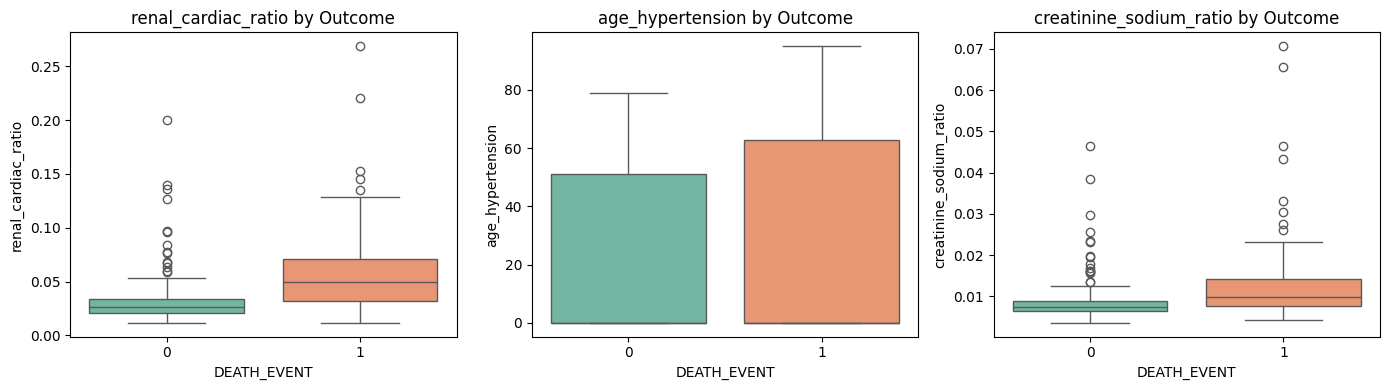

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

new_features = ['renal_cardiac_ratio', 'age_hypertension', 'creatinine_sodium_ratio']

# 1. Summary statistics of the new features
print("=== Summary Statistics of Engineered Features ===")
display(df[new_features].describe().T)

# 2. Mean comparison between survivors (0) and non-survivors (1)
print("\n=== Mean Values: Survived (0) vs Died (1) ===")
display(df.groupby('DEATH_EVENT')[new_features].mean().round(4).T)

# 3. Correlation with DEATH_EVENT (ranked among all features)
corr = df.corr()
print("\n=== Top Correlations with DEATH_EVENT ===")
display(corr[['DEATH_EVENT']].sort_values(by='DEATH_EVENT', ascending=False))

# 4. Boxplots for visual separation
plt.figure(figsize=(14, 4))
for i, col in enumerate(new_features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x='DEATH_EVENT', y=col, data=df, palette='Set2')
    plt.title(f"{col} by Outcome")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier

# Setup 5-fold stratified cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Calculate positive class imbalance weight (~2.1)
pos_weight = (y == 0).sum() / (y == 1).sum()

models = {
    "LightGBM": lgb.LGBMClassifier(
        scale_pos_weight=pos_weight,
        n_estimators=60,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbose=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=4,
        class_weight='balanced',
        random_state=42
    ),
    "CatBoost": CatBoostClassifier(
        scale_pos_weight=pos_weight,
        iterations=100,
        depth=3,
        learning_rate=0.04,
        random_seed=42,
        verbose=0
    )
}

results = {name: {'roc_auc': [], 'pr_auc': [], 'brier': []} for name in models}

# Run Cross-Validation
for train_idx, val_idx in skf.split(X, y):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_val)[:, 1]
        
        results[name]['roc_auc'].append(roc_auc_score(y_val, probs))
        results[name]['pr_auc'].append(average_precision_score(y_val, probs))
        results[name]['brier'].append(brier_score_loss(y_val, probs))

# Print Mean Scores +/- Std
print("=== 5-Fold Stratified Cross-Validation Results ===")
for name in models:
    mean_roc = np.mean(results[name]['roc_auc'])
    mean_pr  = np.mean(results[name]['pr_auc'])
    mean_br  = np.mean(results[name]['brier'])
    print(f"\n[{name}]")
    print(f"ROC-AUC:     {mean_roc:.3f} (+/- {np.std(results[name]['roc_auc']):.3f})")
    print(f"PR-AUC:      {mean_pr:.3f}  (+/- {np.std(results[name]['pr_auc']):.3f})")
    print(f"Brier Score: {mean_br:.3f}  (target <= 0.15)")

=== 5-Fold Stratified Cross-Validation Results ===

[LightGBM]
ROC-AUC:     0.784 (+/- 0.075)
PR-AUC:      0.662  (+/- 0.113)
Brier Score: 0.175  (target <= 0.15)

[Random Forest]
ROC-AUC:     0.795 (+/- 0.073)
PR-AUC:      0.664  (+/- 0.112)
Brier Score: 0.174  (target <= 0.15)

[CatBoost]
ROC-AUC:     0.798 (+/- 0.060)
PR-AUC:      0.676  (+/- 0.118)
Brier Score: 0.178  (target <= 0.15)


In [6]:
from sklearn.ensemble import VotingClassifier

# Build the Soft-Voting Ensemble
ensemble = VotingClassifier(
    estimators=[
        ('catboost', models['CatBoost']),
        ('rf', models['Random Forest']),
        ('lgbm', models['LightGBM'])
    ],
    voting='soft'
)

# 5-fold cross-validation by directly averaging predicted probabilities
ensemble_roc = []
ensemble_pr = []
ensemble_brier = []

for train_idx, val_idx in skf.split(X, y):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    # Fit each model on the training fold
    models['CatBoost'].fit(X_tr, y_tr)
    models['Random Forest'].fit(X_tr, y_tr)
    models['LightGBM'].fit(X_tr, y_tr)
    
    # Get probability predictions from all three
    p_cat = models['CatBoost'].predict_proba(X_val)[:, 1]
    p_rf  = models['Random Forest'].predict_proba(X_val)[:, 1]
    p_lgb = models['LightGBM'].predict_proba(X_val)[:, 1]
    
    # Soft Voting: Simple average of predicted probabilities
    p_ensemble = (p_cat + p_rf + p_lgb) / 3.0
    
    # Metrics
    ensemble_roc.append(roc_auc_score(y_val, p_ensemble))
    ensemble_pr.append(average_precision_score(y_val, p_ensemble))
    ensemble_brier.append(brier_score_loss(y_val, p_ensemble))

print("=== Soft-Voting Ensemble (CatBoost + RF + LightGBM) ===")
print(f"ROC-AUC:     {np.mean(ensemble_roc):.3f} (+/- {np.std(ensemble_roc):.3f})")
print(f"PR-AUC:      {np.mean(ensemble_pr):.3f}  (+/- {np.std(ensemble_pr):.3f})")
print(f"Brier Score: {np.mean(ensemble_brier):.3f}")

=== Soft-Voting Ensemble (CatBoost + RF + LightGBM) ===
ROC-AUC:     0.797 (+/- 0.071)
PR-AUC:      0.668  (+/- 0.129)
Brier Score: 0.174


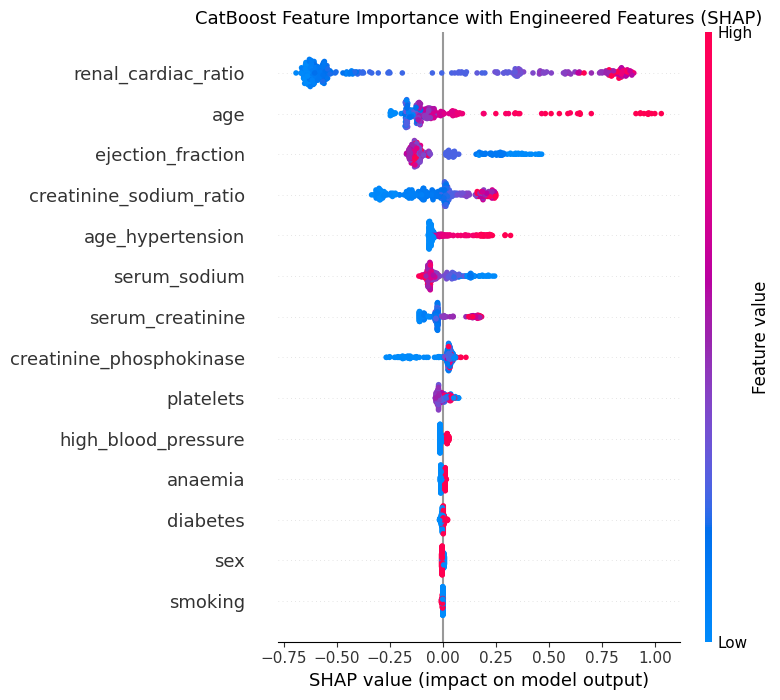

In [7]:
import shap
import matplotlib.pyplot as plt

# 1. Fit final CatBoost model on all data
final_model = models['CatBoost']
final_model.fit(X, y)

# 2. Compute Tree SHAP values on engineered features
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X)

# 3. Global Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X, show=False)
plt.title("CatBoost Feature Importance with Engineered Features (SHAP)", fontsize=13)
plt.tight_layout()
plt.show()

In [8]:
import joblib

# Bundle the model and the expected feature order
artifacts = {
    'model': final_model,
    'features': list(X.columns)
}

joblib.dump(artifacts, 'final_catboost_clinical_model.pkl')
print("Model saved successfully as 'final_catboost_clinical_model.pkl'")

Model saved successfully as 'final_catboost_clinical_model.pkl'
